# BNH – Housing Loan Default Risk

## 1. Imports

In [1]:
print("→ Imports...")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

sns.set_style("whitegrid")
print("✓ OK")

→ Imports...
✓ OK


## 2. Chargement des données

In [2]:
print("Chargement Lending Club...")
df = pd.read_csv("../data/raw/lending_club_sample.csv", low_memory=False)
print(f"{df.shape[0]} lignes x {df.shape[1]} colonnes")
df[['loan_amnt', 'term', 'annual_inc', 'dti', 'fico_range_low', 'loan_status', 'application_type']].head()

Chargement Lending Club...
42538 lignes x 115 colonnes


,loan_amnt,term,annual_inc,dti,fico_range_low,loan_status,application_type
0,5000.0,36 months,24000.0,27.65,735.0,Fully Paid,INDIVIDUAL
1,2500.0,60 months,30000.0,1.00,740.0,Charged Off,INDIVIDUAL
2,2400.0,36 months,12252.0,8.72,735.0,Fully Paid,INDIVIDUAL
3,10000.0,36 months,49200.0,20.00,690.0,Fully Paid,INDIVIDUAL
4,3000.0,60 months,80000.0,17.94,695.0,Current,INDIVIDUAL


## 3. Filtrage
On garde uniquement les prêts terminés (remboursés ou en défaut).  
Les prêts encore en cours n’ont pas d’issue connue.


In [3]:
print("Filtrage...")
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off', 'Default'])].copy()
print(f"{df.shape[0]} prets avec statut final")
print(f"Taux de defaut : {df['loan_status'].isin(['Charged Off', 'Default']).mean():.1%}")

Filtrage...
39240 prets avec statut final
Taux de defaut : 14.4%


## 4. Colonnes BNH
Création de variables adaptées au contexte algérien.


In [4]:
print("Creation des colonnes BNH...")
np.random.seed(42)

df['loan_id'] = df['id'].astype(str)
df['loan_amount_da'] = (df['loan_amnt'] * 150).astype(int)
df['term_months'] = df['term'].str.extract(r'(\d+)').astype(int)
df['fico_like_score'] = df['fico_range_low'].astype(int)
df['dti'] = (df['dti'] / 100).clip(0, 1)
df['default'] = df['loan_status'].isin(['Charged Off', 'Default']).astype(int)

df['income_snmg_multiple'] = (df['annual_inc'] / 28000).clip(1.5, 8).round(2)
df['program'] = np.random.choice(['LPA', 'AADL', 'Rural', 'Other'], len(df), p=[0.45, 0.35, 0.12, 0.08])
df['subsidy_da'] = np.where(df['program'].isin(['LPA', 'AADL']),
                            np.random.choice([400_000, 700_000, 1_000_000], len(df)), 0).astype(int)
df['co_borrower'] = (df['application_type'] == 'JOINT').astype(int)
df['region'] = np.random.choice(['Alger', 'Oran', 'Constantine', 'Other'], len(df), p=[0.4, 0.2, 0.15, 0.25])
df['property_value_da'] = (df['loan_amount_da'] / np.random.uniform(0.55, 0.90, len(df))).astype(int)
df['ltv'] = (df['loan_amount_da'] / df['property_value_da']).round(3)
df['has_subsidy'] = (df['subsidy_da'] > 0).astype(int)

print("Colonnes creees")
df[['loan_id', 'program', 'income_snmg_multiple', 'subsidy_da', 'dti', 'ltv', 'fico_like_score', 'default']].head()

Creation des colonnes BNH...
Colonnes creees


,loan_id,program,income_snmg_multiple,subsidy_da,dti,ltv,fico_like_score,default
0,1077501,LPA,1.50,400000,0.2765,0.836,735,0
1,1077430,Other,1.50,0,0.0100,0.755,740,1
2,1077175,AADL,1.50,1000000,0.0872,0.746,735,0
3,1076863,AADL,1.76,400000,0.2000,0.779,690,0
5,1075269,LPA,1.50,1000000,0.1120,0.891,730,0


## 5. Nettoyage

In [5]:
print("Nettoyage...")
before = df.shape[0]
df = df[(df['ltv'].between(0.4, 1.1)) & (df['dti'].between(0.05, 0.6))].copy()
df = df.dropna(subset=['fico_like_score', 'dti'])
print(f"{before} → {df.shape[0]} lignes")

Nettoyage...
39240 → 34136 lignes


## 6. Analyse exploratoire

C:\Users\wajes\AppData\Local\Temp\ipykernel_31380\2066374480.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(['Bon', 'Defaut'])


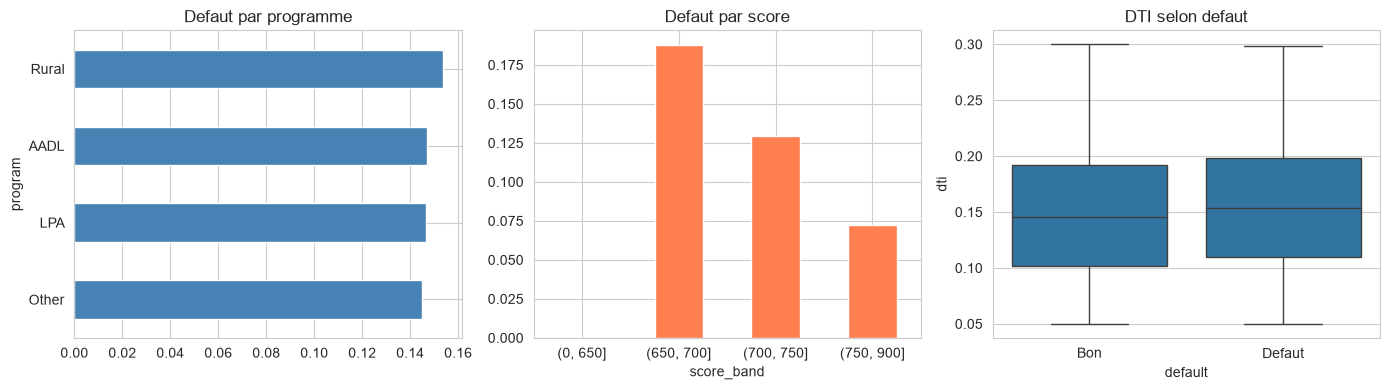

OK


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

df.groupby('program')['default'].mean().sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Defaut par programme')

df['score_band'] = pd.cut(df['fico_like_score'], [0, 650, 700, 750, 900])
df.groupby('score_band', observed=True)['default'].mean().plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Defaut par score')
axes[1].tick_params(axis='x', rotation=0)

sns.boxplot(data=df, x='default', y='dti', ax=axes[2])
axes[2].set_title('DTI selon defaut')
axes[2].set_xticklabels(['Bon', 'Defaut'])

plt.tight_layout()
plt.show()
print("OK")

## 7. Modèle
Régression logistique (simple et interprétable).


In [7]:
print("Entrainement...")
features = ['income_snmg_multiple', 'ltv', 'dti', 'fico_like_score', 'term_months', 'co_borrower', 'has_subsidy']
X, y = df[features], df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

pipeline = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1000))])
pipeline.fit(X_train, y_train)

auc = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1])
print(f"AUC : {auc:.3f}")

coef = pd.Series(pipeline.named_steps['model'].coef_[0], index=features).sort_values()
print(coef.round(3))

df['pd_score'] = pipeline.predict_proba(X)[:, 1]
df['pd_decile'] = pd.qcut(df['pd_score'], 10, labels=False) + 1
print("Scores calcules!")

Entrainement...
AUC : 0.664
fico_like_score        -0.399
income_snmg_multiple   -0.216
has_subsidy            -0.016
ltv                    -0.002
co_borrower             0.000
dti                     0.018
term_months             0.423
dtype: float64
Scores calcules!


## 8. Export Pour Power BI

In [8]:
# Agregats utiles pour le dashboard
summary = df.groupby(["program", "region"]).agg(
    loans=("loan_id", "count"),
    default_rate=("default", "mean"),
    avg_pd=("pd_score", "mean"),
    avg_dti=("dti", "mean"),
    avg_ltv=("ltv", "mean"),
).reset_index().round(3)

decile_summary = df.groupby("pd_decile").agg(
    loans=("loan_id", "count"),
    actual_default_rate=("default", "mean"),
    avg_predicted_pd=("pd_score", "mean"),
).reset_index().round(3)


df.to_csv('../outputs/tables/loans_detail.csv', index=False)
summary.to_csv('../outputs/tables/summary_by_program_region.csv', index=False)
decile_summary.to_csv('../outputs/tables/decile_calibration.csv', index=False)

print("Fichiers exportes pour Power BI :")
print(f"  - loans_detail.csv")
print(f"  - summary_by_program_region.csv")
print(f"  - decile_calibration.csv")

Fichiers exportes pour Power BI :
  - loans_detail.csv
  - summary_by_program_region.csv
  - decile_calibration.csv
